# Single-Layer Neural Networks
## 4.1 Linear Model: a Single Neuron

**Model.** A linear neuron computes a weighted sum of its inputs:

$$a = \mathbf{w}^T\mathbf{x}$$

- $\mathbf{x} \in \mathbb{R}^{D}$: one input sample (a row of the data matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$)
- $\mathbf{w} \in \mathbb{R}^{D}$: the adaptive weights; the bias $w_0$ is included by adding a constant feature $x_0 = 1$
- $a$: the neuron's output (activation), a single number

**Noise assumption.** Each label is the model's output plus Gaussian noise:
$y^n = \mathbf{w}^T\mathbf{x}^n + \epsilon^n$, with $\epsilon^n \sim \mathcal{N}(0, \sigma^2)$.

**Loss.** The squared loss adds up the squared gaps (residuals) $\epsilon^n = y^n - \mathbf{w}^T\mathbf{x}^n$ over all samples:

$$S(\mathbf{w}) = \frac{1}{2}\sum_{n=1}^{N}\left(y^n - \mathbf{w}^T\mathbf{x}^n\right)^2 = \frac{1}{2}(\mathbf{y} - \mathbf{X}\mathbf{w})^T(\mathbf{y} - \mathbf{X}\mathbf{w})$$

$S$ is a scalar: $(1 \times N)(N \times 1) = 1 \times 1$. It measures how far the predictions are from the true labels overall.

**Why squares?** Under Gaussian noise, the log-likelihood is
$\log p(\mathbf{y}\mid\mathbf{X},\mathbf{w}) = -\frac{N}{2}\log(2\pi\sigma^2) - \frac{1}{\sigma^2}S(\mathbf{w})$,
so **maximising the likelihood = minimising $S$** (minimising the negative log-likelihood).
A different noise model gives a different loss: Laplace noise leads to the absolute loss $\sum_n |\epsilon^n|$, which is more robust to outliers.

In [57]:
import numpy as np
import matplotlib.pyplot as plt


In [58]:
# ---- Choices----
N = 20   # Number of samples
D = 2   # number of features 
R = 200 # Range of seed
sigma = 0.3 # noise std
x_low, x_high = -1, 1 
w_true = np.array([1, 2, 3])


In [60]:
def make_data(N, D, sigma, w_true, x_low, x_high, rng):
    X_raw = rng.uniform(x_low, x_high, size=(N, D))
    X = np.hstack([np.ones((X_raw.shape[0], 1)),X_raw])
    noise = rng.normal(0, sigma, size=N)

    dot_prod = X @ w_true
    y = dot_prod + noise
    return X, y
def fit_closed_form(X, y): 
    X_t = X.transpose()
    A = X_t @ X
    B = X_t @ y
    w_hat = np.linalg.solve(A, B)
    return w_hat
    

In [63]:
Ns = [20, 50, 100, 200, 500, 1000, 2000, 5000]
mean_errors = []
for N in Ns:
    errors = []
    for seed in range(R):
        rng = np.random.default_rng(seed)
        X, y = make_data(N, D, sigma, w_true, x_low, x_high, rng)
        w_hat = fit_closed_form(X, y)
        errors.append(np.abs(w_hat - w_true))
    mean_errors.append(np.mean(errors, axis=0))
mean_errors = np.array(mean_errors)
print(mean_errors.shape)

(8, 3)


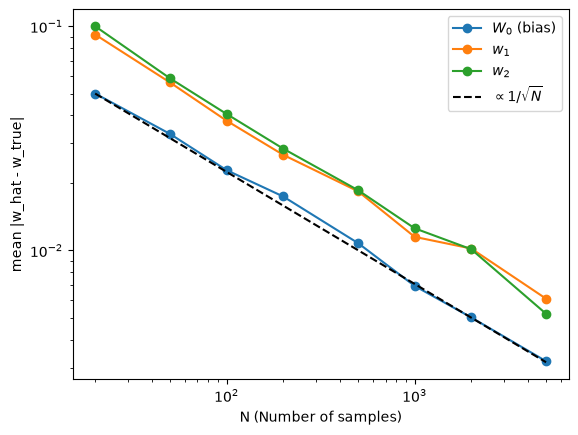

In [68]:
Ns = np.array(Ns)
ref = mean_errors[0, 0] * np.sqrt(Ns[0] / Ns)
mean_errors[:, 0] # All rows and column 0
labels = ["$w_0$ (bias)", "$w_1$", "$w_2$"]
for k in range(3):
    plt.loglog(Ns, mean_errors[:, k], "o-", label = labels[k])
plt.xlabel("N (Number of samples)")
plt.ylabel("mean |w_hat - w_true|")
plt.loglog(Ns, ref, "k--", label=r"$\propto 1/\sqrt{N}$")
plt.legend()
plt.show()

**Why is not the estimate exact? what would $\hat{w}$ be if sigma = 0?** <br>
There is noise introduced and which add some offset to the prediction so the estimate is not exact. <br> Wilhe sigma = 0, the $\hat{w}$ very close to the w_true
<br> **Why is the bias worst here?** <br>
The bias is always less accurate because: a weight is estimated precisely when changing it changes the predictions a lot, <br> and the bias multiplies a constant 1 while $w_1, w_2$ multiply inputs up to 200.

### Experiment: why is the bias estimated worse than the feature weights?

With features drawn from $[1, 200]$ the bias $w_0$ had the largest error. **Hypothesis:** a weight is estimated
precisely when changing it changes the predictions a lot. Changing $w_d$ by $\delta$ moves every prediction by
$\delta \cdot x_d$, but changing the bias moves it only by $\delta \cdot 1$. So large features give their weights
more "leverage", and the bias the least. **Test:** rescale the features to $[-1, 1]$, where a typical $|x_d| < 1$.
The bias should then become the *most* accurate weight.

|| features in $[1, 200]$|features in $[-1, 1]$ |
|---|---|---|
| $\lvert \hat w_0 - w_0 \rvert$ (bias) | 0.0079 (worst) | 0.012 (best) |
| $\lvert \hat w_1 - w_1 \rvert$ | 0.0006 | 0.056 |
| $\lvert \hat w_2 - w_2 \rvert$ | 0.0008 | 0.07 |

**Result:** the prediction holds, and the ranking flips. The feature-weight errors also grew about 100×, because the
features shrank about 100× while the noise stayed at $\sigma = 0.3$. The accuracy of $\hat{\mathbf{w}}$ depends on
the noise *relative to the size of the signal*, not on the algorithm alone.

With $\sigma = 0$, the closed form recovers $\mathbf{w}$ up to floating-point rounding ($\sim 10^{-12}$ to $10^{-14}$),
and `np.linalg.solve` is slightly more accurate than `np.linalg.inv`.

In [54]:
errors = [np.array([0.01, 0.05, 0.07]),   # seed 0
          np.array([0.02, 0.04, 0.06]),   # seed 1
          np.array([0.01, 0.06, 0.08]),   # seed 2
          np.array([0.02, 0.05, 0.07])]   # seed 3
E = np.array(errors)
print(E.shape)    # (4, 3)

(4, 3)


In [55]:
print(np.mean(E, axis=0))
print(np.mean(E, axis=1))
print(np.mean(E))

[0.015 0.05  0.07 ]
[0.04333333 0.04       0.05       0.04666667]
0.045000000000000005
